# Fine-Tuning MobileNetV2 for Pet Breed Classification

This Jupyter Notebook demonstrates the process of fine-tuning a pre-trained MobileNetV2 model for the Oxford-IIIT Pet Dataset. We'll cover data loading and preprocessing, building a custom classification head, a two-phase training strategy (feature extraction followed by fine-tuning), and model evaluation with visualizations.

---

## 1. Setup and Environment Configuration

This section imports necessary libraries like TensorFlow, Keras, and Matplotlib, and sets a random seed for reproducibility. It also prints the versions of TensorFlow and Keras being used.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import layers, models, optimizers
from keras.callbacks import EarlyStopping, TerminateOnNaN, ReduceLROnPlateau

# Set random seed for reproducibility across runs
keras.utils.set_random_seed(23)

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)

2025-06-26 18:53:45.695765: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750956826.694630     922 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750956826.966143     922 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1750956829.537165     922 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1750956829.537188     922 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1750956829.537190     922 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0
Keras Version: 3.10.0


## 2. Load and Preprocess the Dataset

Here, we load the oxford_iiit_pet dataset using tfds.load. We then define a preprocessing function specifically designed for MobileNetV2, which resizes images to 224x224 pixels and normalizes pixel values to the range [-1, 1]. The datasets are then batched and prefetched for efficient training.

In [3]:
(train_raw, val_raw), info = tfds.load(
    'oxford_iiit_pet',
    split=['train', 'test'],
    with_info=True,
    as_supervised=True # Returns (image, label) tuples
)

print("\n--- Dataset Information ---")
print(info.description)
print("\nSplits:", info.splits)
print("Features:", info.features)

num_classes = info.features['label'].num_classes
image_size = (224, 224) # Standard input size for MobileNetV2

# Using the specific preprocessing function for MobileNetV2
def preprocess_image_for_mobilenet(image, label):
    image = tf.image.resize(image, image_size) # Resize to 224x224
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image) # Normalizes to [-1, 1]
    return image, label

# Configure batching and prefetching
batch_size = 32

# Apply preprocessing *after* data augmentation if augmentation is done within the dataset pipeline
# Or, if augmentation layers are added to the model, preprocess_image_for_mobilenet should still be applied first.
train_ds = train_raw.map(preprocess_image_for_mobilenet).shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.map(preprocess_image_for_mobilenet).batch(batch_size).prefetch(tf.data.AUTOTUNE)

print(f"\nDataset preprocessed. Image size: {image_size}, Batch size: {batch_size}")
print(f"Number of classes (breeds): {num_classes}")

I0000 00:00:1750956899.355542     922 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6



--- Dataset Information ---
The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
images for each class. The images have large variations in scale, pose and
lighting. All images have an associated ground truth annotation of breed and
species. Additionally, head bounding boxes are provided for the training split,
allowing using this dataset for simple object detection tasks. In the test
split, the bounding boxes are empty.

Splits: {'train': <SplitInfo num_examples=3680, num_shards=4>, 'test': <SplitInfo num_examples=3669, num_shards=4>}
Features: FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})

Dataset preprocessed. Image size: (224, 224)

## 3. Display Sample Preprocessed Images

This section visualizes a few sample images from the training dataset after MobileNetV2 preprocessing. Note that the images are rescaled from [-1, 1] to [0, 1] for proper display with Matplotlib.


--- Displaying Sample Images from Training Dataset (post-MobileNetV2 preprocess) ---


2025-06-26 18:55:02.592911: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:387] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
2025-06-26 18:55:03.108040: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


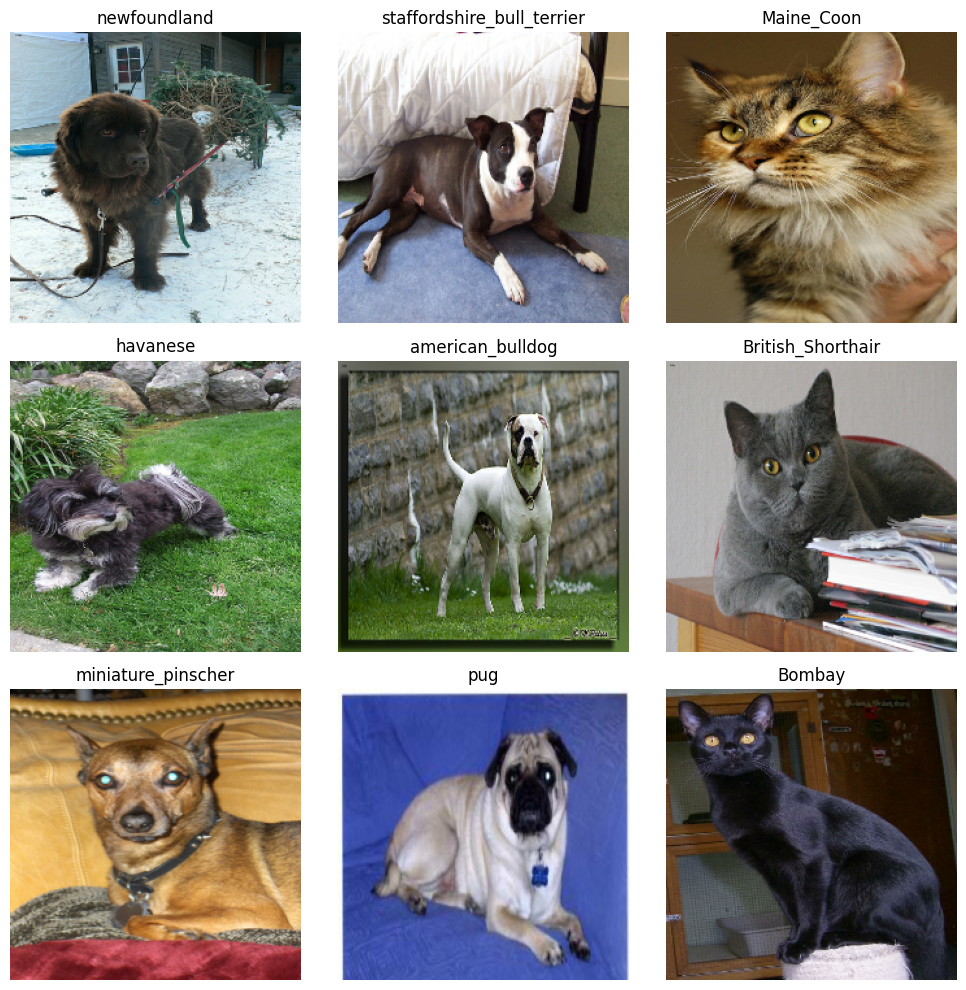

--- Sample images displayed successfully ---


In [4]:
print("\n--- Displaying Sample Images from Training Dataset (post-MobileNetV2 preprocess) ---")
class_names = info.features['label'].names

plt.figure(figsize=(10, 10))
for i, (image, label) in enumerate(train_ds.unbatch().take(9)): # Take 9 individual images
    ax = plt.subplot(3, 3, i + 1)
    display_image = (image.numpy() + 1) / 2
    plt.imshow(display_image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")
plt.tight_layout()
plt.show()
print("--- Sample images displayed successfully ---")

## 4. Load Pre-trained Base Model and Build Classification Head

We load the MobileNetV2 model pre-trained on ImageNet, excluding its top classification layer (include_top=False). Initially, the base model's layers are frozen to prevent their weights from being updated during the first training phase. We then add data augmentation layers and a custom classification head on top of the frozen base model. The classification head includes Dense layers, BatchNormalization, and Dropout for better performance.

In [5]:
base_model = keras.applications.MobileNetV2(
    input_shape=image_size + (3,),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False # Freeze initially

print("\n--- Base Model (MobileNetV2) Loaded and Frozen ---")
print("Base Model Summary (Feature Extractor Part):")
base_model.summary()

# Build the Classification Head and Full Model
inputs = keras.Input(shape=image_size + (3,))

# Data Augmentation Layers
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x) # Rotate by +/- 5 degrees
x = layers.RandomZoom(0.1)(x) # Zoom by +/- 10%

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)

# Complex Classification Head
x = layers.Dense(128, activation='relu')(x) # Added an intermediate Dense layer
x = layers.BatchNormalization()(x) # Added Batch Normalization
x = layers.Dropout(0.3)(x) # Increased dropout rate slightly

outputs = layers.Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

print("\n--- Full Model Structure (Phase 1: Feature Extraction) ---")
model.summary()


--- Base Model (MobileNetV2) Loaded and Frozen ---
Base Model Summary (Feature Extractor Part):


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 37)             │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,237 (9.26 MB)

 Trainable params: 168,997 (660.14 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

## 5. Training Phase 1: Feature Extraction

In this first phase, only the newly added classification head is trained, while the base MobileNetV2 model remains frozen. This allows the new layers to learn to interpret the features extracted by the pre-trained model. We use the Adam optimizer and sparse_categorical_crossentropy loss. Callbacks include EarlyStopping to prevent overfitting and ReduceLROnPlateau to dynamically adjust the learning rate.

In [7]:
# Compile and Train (Phase 1: Feature Extraction)
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Training Phase 1: Feature Extraction ---")
epochs_phase1 = 20 # Keep epochs relatively high for EarlyStopping to work

# ReduceLROnPlateau callback for Phase 1
callbacks_phase1 = [
    TerminateOnNaN(),
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1), # Increased patience slightly
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=1, min_lr=1e-6) # Reduce LR on plateau
]

history_phase1 = model.fit(
    train_ds,
    epochs=epochs_phase1,
    validation_data=val_ds,
    callbacks=callbacks_phase1
)

# Check if val_loss is empty or if the last loss value is NaN
early_stopped_phase1_nan = np.isnan(history_phase1.history['loss'][-1]) if history_phase1.history['loss'] else False
early_stopped_phase1_val_loss_issue = not history_phase1.history['val_loss'] # Check if val_loss list is empty

if early_stopped_phase1_nan or early_stopped_phase1_val_loss_issue:
    print("\n¡ADVERTENCIA: El entrenamiento de la Fase 1 se detuvo prematuramente (NaN o problema de val_loss)!")
    print("No se procederá con la Fase 2 si hubo un problema grave.")
    if early_stopped_phase1_nan:
        print("La pérdida es NaN. No se pueden generar gráficos ni predicciones significativas.")
    exit()

epochs_run_phase1 = len(history_phase1.history['loss'])
epochs_phase2_desired = 20
total_epochs = epochs_run_phase1 + epochs_phase2_desired

print(f"\nPhase 1 completed in {epochs_run_phase1} epochs.")


--- Training Phase 1: Feature Extraction ---
Epoch 1/20


I0000 00:00:1750956911.090110    1039 cuda_dnn.cc:529] Loaded cuDNN version 90501


115/115 ━━━━━━━━━━━━━━━━━━━━ 23s 119ms/step - accuracy: 0.5080 - loss: 1.9494 - val_accuracy: 0.8534 - val_loss: 0.5334 - learning_rate: 0.0010
Epoch 2/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.8731 - loss: 0.4536 - val_accuracy: 0.8817 - val_loss: 0.3997 - learning_rate: 0.0010
Epoch 3/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.9001 - loss: 0.3499 - val_accuracy: 0.8831 - val_loss: 0.3803 - learning_rate: 0.0010
Epoch 4/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - accuracy: 0.9231 - loss: 0.2597 - val_accuracy: 0.8866 - val_loss: 0.3767 - learning_rate: 0.0010
Epoch 5/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.9372 - loss: 0.1982 - val_accuracy: 0.8940 - val_loss: 0.3526 - learning_rate: 0.0010
Epoch 6/20
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9443 - loss: 0.1787
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 83ms/step - accuracy: 0.9444 - loss: 0.1785

## 6. Training Phase 2: Fine-tuning the Base Model

After the feature extraction phase, we unfreeze the base MobileNetV2 model (or at least parts of it) to allow for fine-tuning. A significantly lower learning rate is used to avoid corrupting the pre-trained weights. Batch Normalization layers are kept frozen during fine-tuning as per best practices. The model is recompiled, and training continues with the same set of callbacks.

In [9]:
# Only proceed to Phase 2 if Phase 1 did not have NaN loss
if not early_stopped_phase1_nan:
    # Fine-tune the Base Model (Phase 2: Fine-tuning)
    base_model.trainable = True
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.0001), # Significantly reduced learning rate for fine-tuning
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Model Recompiled for Fine-tuning ---")
    print(f"Number of trainable variables in the full model (after unfreezing base model): {len(model.trainable_variables)}")

    # ReduceLROnPlateau callback for Phase 2
    callbacks_phase2 = [
        TerminateOnNaN(),
        EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1), # Increased patience slightly
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=1, min_lr=1e-7) # Reduce LR on plateau, even lower min_lr
    ]

    history_phase2 = model.fit(
        train_ds,
        epochs=total_epochs, # Continues up to total epochs or EarlyStopping
        initial_epoch=epochs_run_phase1, # Continues training from where phase 1 ended
        validation_data=val_ds,
        callbacks=callbacks_phase2
    )
    epochs_run_phase2 = len(history_phase2.history['loss']) - epochs_run_phase1


--- Model Recompiled for Fine-tuning ---
Number of trainable variables in the full model (after unfreezing base model): 58
Epoch 9/28
115/115 ━━━━━━━━━━━━━━━━━━━━ 23s 150ms/step - accuracy: 0.9519 - loss: 0.1617 - val_accuracy: 0.8253 - val_loss: 0.7004 - learning_rate: 1.0000e-04
Epoch 10/28
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 161ms/step - accuracy: 0.9449 - loss: 0.1650 - val_accuracy: 0.8297 - val_loss: 0.6521 - learning_rate: 1.0000e-04
Epoch 11/28
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9498 - loss: 0.1513
Epoch 11: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 135ms/step - accuracy: 0.9498 - loss: 0.1515 - val_accuracy: 0.7975 - val_loss: 0.7502 - learning_rate: 1.0000e-04
Epoch 12/28
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 160ms/step - accuracy: 0.9752 - loss: 0.0842 - val_accuracy: 0.8858 - val_loss: 0.4041 - learning_rate: 5.0000e-05
Epoch 13/28
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.9928 - loss: 0

## 7. Evaluate the Model and Visualize Performance

After both training phases, the model's performance is evaluated on the validation dataset. The training histories from both phases are combined to generate comprehensive plots of training and validation accuracy and loss over all epochs, providing insights into the model's learning progression and potential overfitting. Detailed metrics per epoch are also printed.


--- Final Model Evaluation ---
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8979 - loss: 0.3696
Final Loss on Validation (Test) Set: 0.3606
Final Accuracy on Validation (Test) Set: 0.8983


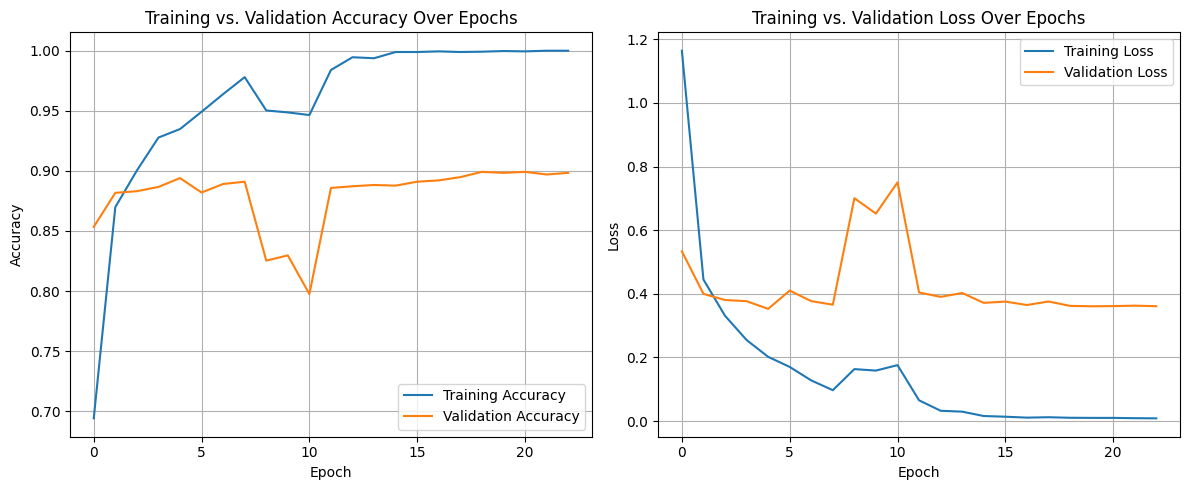


--- Metrics Per Epoch (Detailed Breakdown) ---
Epoch 1/23:
   Training: Accuracy=0.6940, Loss=1.1641
   Validation: Accuracy=0.8534, Loss=0.5334
Epoch 2/23:
   Training: Accuracy=0.8698, Loss=0.4448
   Validation: Accuracy=0.8817, Loss=0.3997
Epoch 3/23:
   Training: Accuracy=0.9003, Loss=0.3309
   Validation: Accuracy=0.8831, Loss=0.3803
Epoch 4/23:
   Training: Accuracy=0.9277, Loss=0.2547
   Validation: Accuracy=0.8866, Loss=0.3767
Epoch 5/23:
   Training: Accuracy=0.9348, Loss=0.2017
   Validation: Accuracy=0.8940, Loss=0.3526
Epoch 6/23:
   Training: Accuracy=0.9492, Loss=0.1700
   Validation: Accuracy=0.8820, Loss=0.4099
Epoch 7/23:
   Training: Accuracy=0.9639, Loss=0.1275
   Validation: Accuracy=0.8891, Loss=0.3768
Epoch 8/23:
   Training: Accuracy=0.9780, Loss=0.0968
   Validation: Accuracy=0.8910, Loss=0.3656
Epoch 9/23:
   Training: Accuracy=0.9503, Loss=0.1631
   Validation: Accuracy=0.8253, Loss=0.7004
Epoch 10/23:
   Training: Accuracy=0.9486, Loss=0.1585
   Validation: 

In [10]:
# Evaluate the Model
print("\n--- Final Model Evaluation ---")
loss, accuracy = model.evaluate(val_ds)
print(f"Final Loss on Validation (Test) Set: {loss:.4f}")
print(f"Final Accuracy on Validation (Test) Set: {accuracy:.4f}")

# Show Detailed Statistics and Visualizations
# Combine the history objects from both training phases for comprehensive plotting
history_combined = {
    'accuracy': history_phase1.history['accuracy'] + history_phase2.history['accuracy'],
    'val_accuracy': history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy'],
    'loss': history_phase1.history['loss'] + history_phase2.history['loss'],
    'val_loss': history_phase1.history['val_loss'] + history_phase2.history['val_loss']
}
final_total_epochs_run = len(history_combined['loss'])

plt.figure(figsize=(12, 5))

# Plot Training and Validation Accuracy over epochs
plt.subplot(1, 2, 1)
plt.plot(history_combined['accuracy'], label='Training Accuracy')
plt.plot(history_combined['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy Over Epochs')
plt.legend()
plt.grid(True)

# Plot Training and Validation Loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history_combined['loss'], label='Training Loss')
plt.plot(history_combined['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss Over Epochs')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print detailed metrics for each epoch
print("\n--- Metrics Per Epoch (Detailed Breakdown) ---")
for epoch in range(final_total_epochs_run):
    print(f"Epoch {epoch+1}/{final_total_epochs_run}:")
    print(f"   Training: Accuracy={history_combined['accuracy'][epoch]:.4f}, Loss={history_combined['loss'][epoch]:.4f}")
    print(f"   Validation: Accuracy={history_combined['val_accuracy'][epoch]:.4f}, Loss={history_combined['val_loss'][epoch]:.4f}")

## 8. Visualize Sample Predictions

Finally, this section takes a few sample images from the validation set, makes predictions using the trained model, and displays the images along with their true labels and the model's predicted labels and probabilities. It also shows the top 5 predicted probabilities for each sample.


--- Sample Predictions from Validation (Test) Set ---

--- Displaying predictions from Batch 1 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


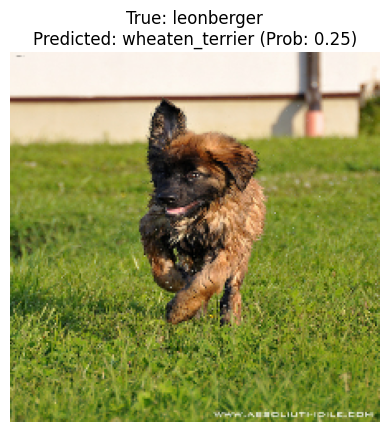

Sample Image 1 (from Batch 1):
   True Class: leonberger
   Model Prediction: wheaten_terrier (Probability: 0.2467)
   Top 5 Predicted Probabilities:
     - wheaten_terrier: 0.2467
     - havanese: 0.1837
     - staffordshire_bull_terrier: 0.1425
     - Siamese: 0.0982
     - leonberger: 0.0893
----------------------------------------


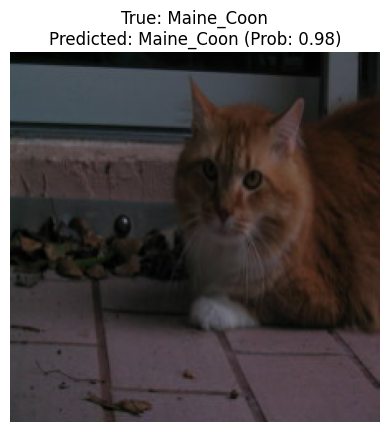

Sample Image 2 (from Batch 1):
   True Class: Maine_Coon
   Model Prediction: Maine_Coon (Probability: 0.9795)
   Top 5 Predicted Probabilities:
     - Maine_Coon: 0.9795
     - Bengal: 0.0182
     - Ragdoll: 0.0012
     - British_Shorthair: 0.0003
     - Abyssinian: 0.0003
----------------------------------------


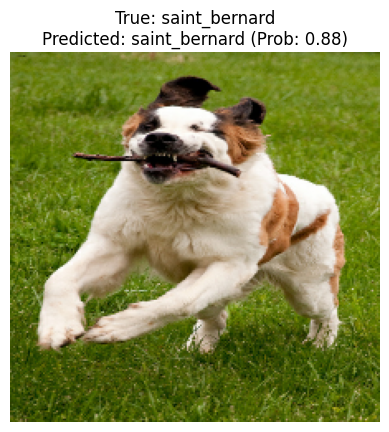

Sample Image 3 (from Batch 1):
   True Class: saint_bernard
   Model Prediction: saint_bernard (Probability: 0.8820)
   Top 5 Predicted Probabilities:
     - saint_bernard: 0.8820
     - american_bulldog: 0.1153
     - leonberger: 0.0004
     - boxer: 0.0004
     - pug: 0.0003
----------------------------------------


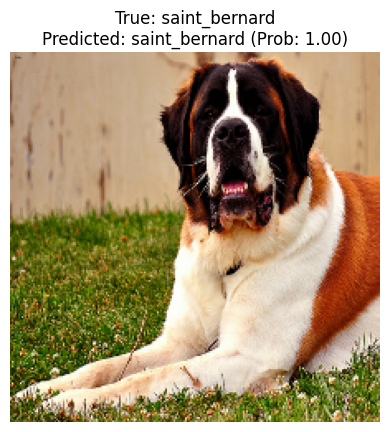

Sample Image 4 (from Batch 1):
   True Class: saint_bernard
   Model Prediction: saint_bernard (Probability: 0.9957)
   Top 5 Predicted Probabilities:
     - saint_bernard: 0.9957
     - boxer: 0.0025
     - american_bulldog: 0.0005
     - wheaten_terrier: 0.0004
     - leonberger: 0.0003
----------------------------------------


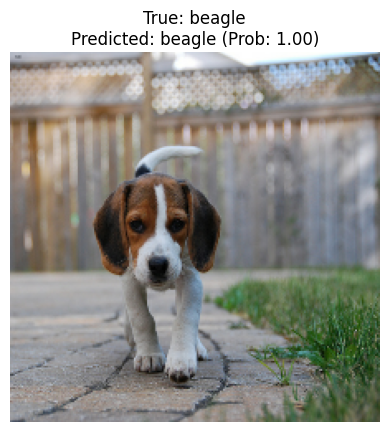

Sample Image 5 (from Batch 1):
   True Class: beagle
   Model Prediction: beagle (Probability: 0.9998)
   Top 5 Predicted Probabilities:
     - beagle: 0.9998
     - Siamese: 0.0000
     - saint_bernard: 0.0000
     - german_shorthaired: 0.0000
     - basset_hound: 0.0000
----------------------------------------

--- Displaying predictions from Batch 2 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


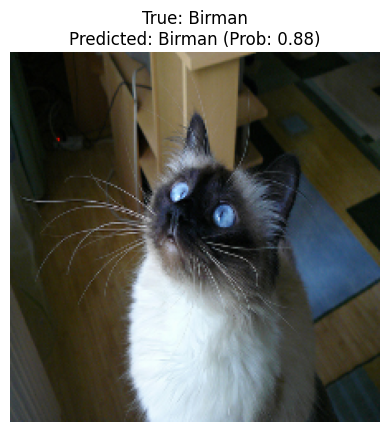

Sample Image 1 (from Batch 2):
   True Class: Birman
   Model Prediction: Birman (Probability: 0.8783)
   Top 5 Predicted Probabilities:
     - Birman: 0.8783
     - Siamese: 0.1181
     - Ragdoll: 0.0024
     - Bombay: 0.0004
     - japanese_chin: 0.0001
----------------------------------------


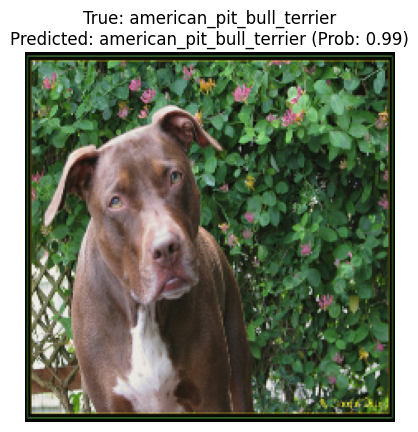

Sample Image 2 (from Batch 2):
   True Class: american_pit_bull_terrier
   Model Prediction: american_pit_bull_terrier (Probability: 0.9868)
   Top 5 Predicted Probabilities:
     - american_pit_bull_terrier: 0.9868
     - staffordshire_bull_terrier: 0.0119
     - chihuahua: 0.0004
     - Sphynx: 0.0001
     - german_shorthaired: 0.0001
----------------------------------------


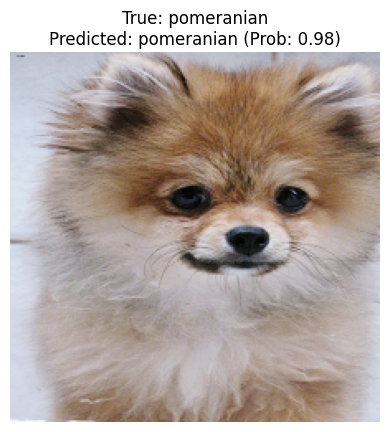

Sample Image 3 (from Batch 2):
   True Class: pomeranian
   Model Prediction: pomeranian (Probability: 0.9805)
   Top 5 Predicted Probabilities:
     - pomeranian: 0.9805
     - Ragdoll: 0.0075
     - japanese_chin: 0.0022
     - Persian: 0.0016
     - keeshond: 0.0016
----------------------------------------


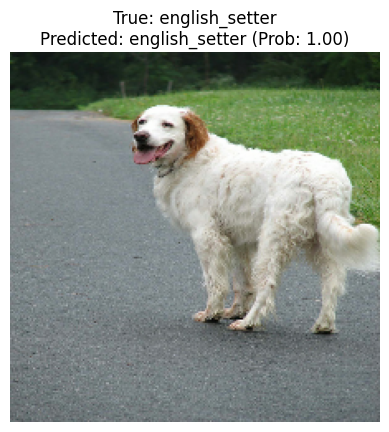

Sample Image 4 (from Batch 2):
   True Class: english_setter
   Model Prediction: english_setter (Probability: 0.9999)
   Top 5 Predicted Probabilities:
     - english_setter: 0.9999
     - great_pyrenees: 0.0000
     - american_bulldog: 0.0000
     - Egyptian_Mau: 0.0000
     - newfoundland: 0.0000
----------------------------------------


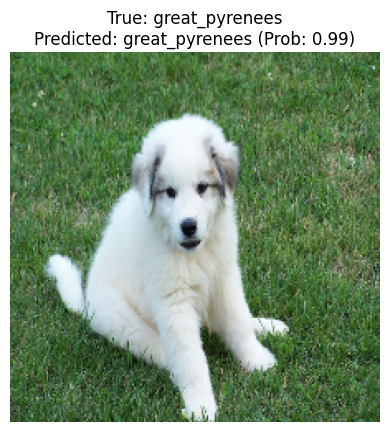

Sample Image 5 (from Batch 2):
   True Class: great_pyrenees
   Model Prediction: great_pyrenees (Probability: 0.9946)
   Top 5 Predicted Probabilities:
     - great_pyrenees: 0.9946
     - samoyed: 0.0023
     - saint_bernard: 0.0015
     - japanese_chin: 0.0003
     - newfoundland: 0.0003
----------------------------------------

--- Displaying predictions from Batch 3 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


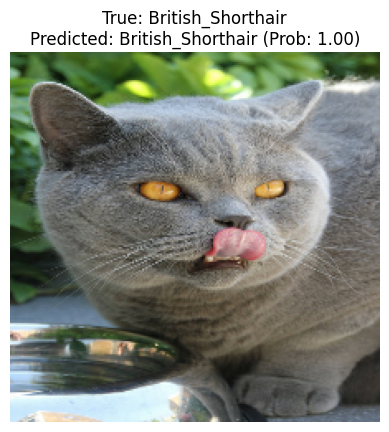

Sample Image 1 (from Batch 3):
   True Class: British_Shorthair
   Model Prediction: British_Shorthair (Probability: 0.9990)
   Top 5 Predicted Probabilities:
     - British_Shorthair: 0.9990
     - Russian_Blue: 0.0010
     - samoyed: 0.0000
     - Siamese: 0.0000
     - Sphynx: 0.0000
----------------------------------------


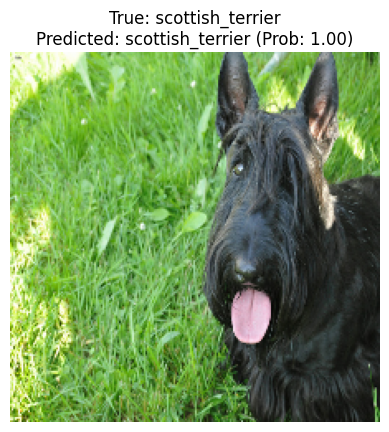

Sample Image 2 (from Batch 3):
   True Class: scottish_terrier
   Model Prediction: scottish_terrier (Probability: 0.9994)
   Top 5 Predicted Probabilities:
     - scottish_terrier: 0.9994
     - staffordshire_bull_terrier: 0.0002
     - Sphynx: 0.0001
     - havanese: 0.0001
     - wheaten_terrier: 0.0000
----------------------------------------


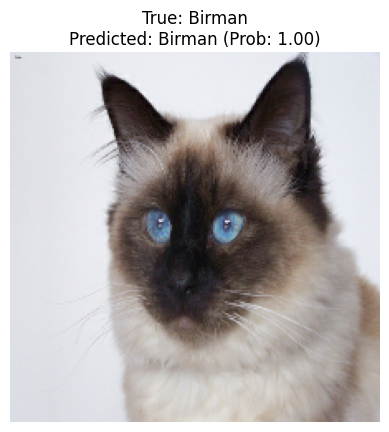

Sample Image 3 (from Batch 3):
   True Class: Birman
   Model Prediction: Birman (Probability: 0.9980)
   Top 5 Predicted Probabilities:
     - Birman: 0.9980
     - Siamese: 0.0008
     - Ragdoll: 0.0007
     - leonberger: 0.0001
     - Bombay: 0.0001
----------------------------------------


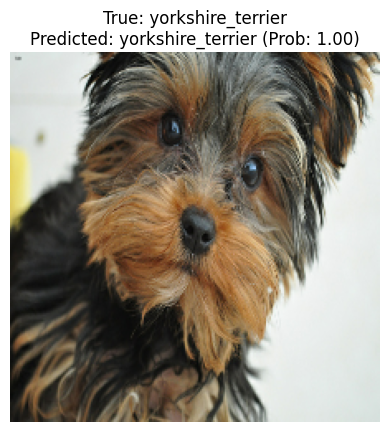

Sample Image 4 (from Batch 3):
   True Class: yorkshire_terrier
   Model Prediction: yorkshire_terrier (Probability: 0.9983)
   Top 5 Predicted Probabilities:
     - yorkshire_terrier: 0.9983
     - havanese: 0.0008
     - english_cocker_spaniel: 0.0001
     - great_pyrenees: 0.0001
     - Maine_Coon: 0.0001
----------------------------------------


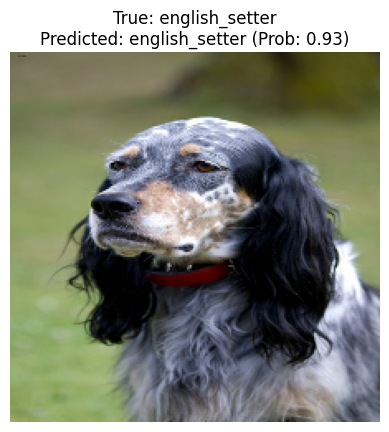

Sample Image 5 (from Batch 3):
   True Class: english_setter
   Model Prediction: english_setter (Probability: 0.9314)
   Top 5 Predicted Probabilities:
     - english_setter: 0.9314
     - english_cocker_spaniel: 0.0652
     - german_shorthaired: 0.0009
     - basset_hound: 0.0005
     - havanese: 0.0005
----------------------------------------


2025-06-26 19:08:37.103807: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [16]:
# Visualize Sample Predictions
print("\n--- Sample Predictions from Validation (Test) Set ---")
class_names = info.features['label'].names

for batch_idx, (images, labels) in enumerate(val_ds.take(3)):
    print(f"\n--- Displaying predictions from Batch {batch_idx + 1} ---")
    predictions = model.predict(images)
    for i in range(min(5, len(images))): # Display up to 5 images from each batch
        predicted_label = np.argmax(predictions[i])
        true_label = labels[i].numpy()

        display_image = (images[i].numpy() + 1) / 2
        plt.imshow(display_image)
        plt.title(f"True: {class_names[true_label]}\nPredicted: {class_names[predicted_label]} (Prob: {predictions[i][predicted_label]:.2f})")
        plt.axis('off')
        plt.show()

        print(f"Sample Image {i+1} (from Batch {batch_idx + 1}):")
        print(f"   True Class: {class_names[true_label]}")
        print(f"   Model Prediction: {class_names[predicted_label]} (Probability: {predictions[i][predicted_label]:.4f})")

        top_5_indices = np.argsort(predictions[i])[-5:][::-1]
        print("   Top 5 Predicted Probabilities:")
        for idx in top_5_indices:
            print(f"     - {class_names[idx]}: {predictions[i][idx]:.4f}")
        print("-" * 40)

# Optional: Save the trained model
# model.save('fine_tuned_oxford_iiit_pet_model_improved.keras')
# print("\nModel saved as 'fine_tuned_oxford_iiit_pet_model_improved.keras'")